# Q15. In which brain area is the neural signal most complex? (stimulus → trial end)

**Measure: Lempel–Ziv complexity (LZc)**, the most widely used signal-complexity measure in neuroscience.
1. The LFP is binarised around its median.
2. LZc counts how many *new* patterns appear while reading the sequence. It's normalised so that a regular signal gives ~0 and white noise ~1.
3. On test signals: a 7 Hz sine gives 0.13, a random walk 0.27, a sine plus noise 0.41, and white noise 1.1.

**Window.** The first **1.0 s after stimulus onset** in each trial, which always lies inside stimulus → trial end. LZc depends on length, and stimulus → trial-end durations vary a lot (the timeout of incorrect trials, pauses). 200 random trials per mouse, 6 channels per area spread over depth.

**Main confound: the power spectrum.** A flatter spectrum, with relatively more fast activity, automatically gives a higher LZc. In Q9, area 1 had the flattest spectrum.
Every window is therefore also scored after **phase randomisation**, which keeps exactly the same power spectrum but scrambles the timing structure.
**LZc / LZc(surrogate)** is the complexity beyond the spectrum: above 1 means more complex than the spectrum alone implies, below 1 means more structured or predictable.

**Robustness checks:**
- bipolar (local) signals;
- stricter **IAAFT** surrogates, which keep both the power spectrum and the distribution of signal values;
- a second measure, **permutation entropy** (how evenly the ordinal patterns of 4 consecutive samples are used);
- a **spike-based** LZc of the population raster (5 units per area, 5-ms bins) against a version with each unit's spikes shuffled in time.

The code lives in `c2p/q15_complexity.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, FS_LFP, RESULTS_DIR, Recording
from c2p import q15_complexity as q
from c2p.stats import area_bootstrap, per_mouse_tests

lfp, spk = q.compute()                    # cached; q.compute(force=True) recomputes (~20 min)
mono = lfp[lfp.reference == "monopolar"]
print(f"{lfp.mouse.nunique()} mice; windows per mouse: {lfp.groupby('mouse').n_windows.max().describe()[['min', '50%']].to_dict()}")

18 mice; windows per mouse: {'min': 200.0, '50%': 200.0}


## 1. What the measure sees (one window per area, one mouse)

Top: 1 s of LFP after stimulus onset. Bottom: the same signal binarised at its median, which is what LZc reads.

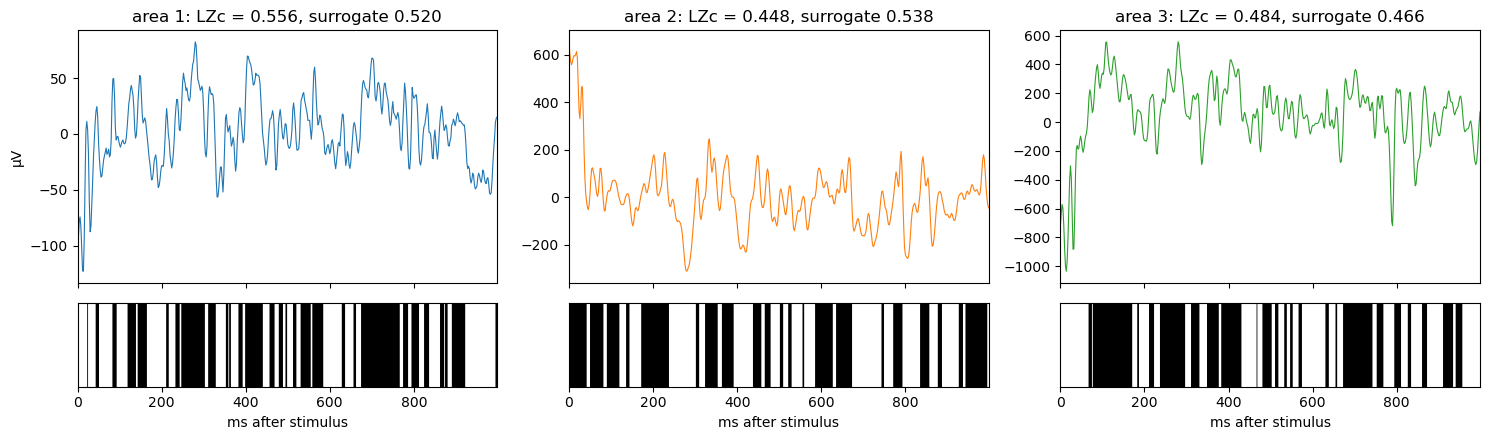

In [2]:
MOUSE = 9
rec = Recording.load(MOUSE)
s0 = int(q.windows(rec)[50] * FS_LFP); n = int(q.WIN * FS_LFP)
fig, axs = plt.subplots(2, 3, figsize=(15, 4.5), gridspec_kw=dict(height_ratios=[3, 1]), sharex=True)
t = np.arange(n) / FS_LFP * 1000
for k, a in enumerate(AREAS):
    x = np.asarray(rec.lfp[a][rec.lfp[a].shape[0] // 2, s0:s0 + n], dtype=float) * 1e6
    axs[0, k].plot(t, x, color=AREA_COLORS[a], lw=0.8)
    axs[0, k].set(title=f"area {a}: LZc = {q.lzc(x):.3f}, surrogate {q.lzc(q.phase_surrogate(x, np.random.default_rng(0))):.3f}", ylabel="µV" if k == 0 else "")
    axs[1, k].imshow((x > np.median(x))[None, :], aspect="auto", cmap="gray_r", extent=[0, t[-1], 0, 1])
    axs[1, k].set(yticks=[], xlabel="ms after stimulus")
fig.tight_layout()

## 2. LZc and its ratio to spectrum-matched surrogates, per mouse

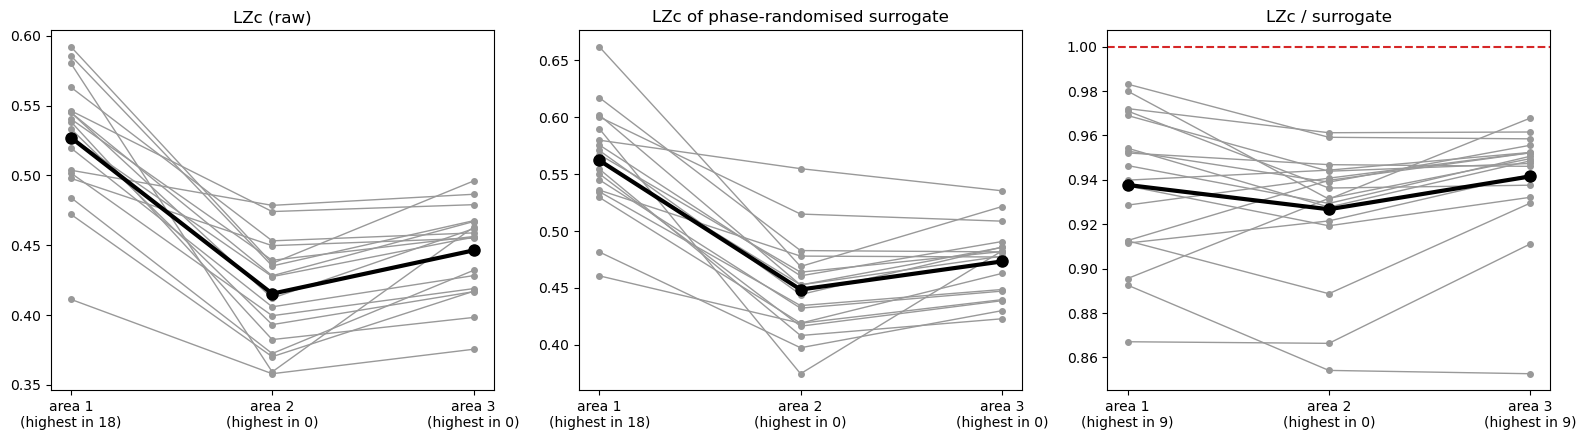

In [3]:
pm = {col: mono.groupby(["mouse", "area"])[col].mean().unstack() for col in ["lzc", "lzc_surr", "lzc_ratio", "pe"]}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, lab) in zip(axs, [("lzc", "LZc (raw)"), ("lzc_surr", "LZc of phase-randomised surrogate"), ("lzc_ratio", "LZc / surrogate")]):
    for m, row in pm[col].iterrows():
        ax.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
    ax.plot(AREAS, pm[col].mean().values, "-o", color="k", lw=3, ms=8)
    if col == "lzc_ratio":
        ax.axhline(1, color="tab:red", ls="--")
    best = pm[col].idxmax(axis=1).value_counts()
    ax.set(xticks=AREAS, xticklabels=[f"area {a}\n(highest in {best.get(a, 0)})" for a in AREAS], title=lab)
fig.tight_layout()

## 3. Statistics for every measure

In [4]:
def summ(t):
    t = t.dropna()
    w = {f"{x} vs {y}": sps.wilcoxon(t[x], t[y]).pvalue for x, y in [(1, 2), (1, 3), (2, 3)]}
    return {**{f"area {a}": t[a].mean() for a in AREAS}, "highest (mean)": f"area {t.mean().idxmax()}",
            "highest in n mice": dict(t.idxmax(axis=1).value_counts().sort_index()),
            "Friedman p": sps.friedmanchisquare(*[t[a] for a in AREAS]).pvalue, **{f"Wilcoxon {k}": v for k, v in w.items()}}

rows = {}
for ref, g in lfp.groupby("reference"):
    for col, lab in [("lzc", "LZc"), ("lzc_surr", "LZc of surrogate"), ("lzc_ratio", "LZc / surrogate"), ("pe", "permutation entropy")]:
        rows[f"LFP {ref}: {lab}"] = summ(g.groupby(["mouse", "area"])[col].mean().unstack())
for col, lab in [("lzc_spikes", "LZc"), ("lzc_spikes_ratio", "LZc / time-shuffled")]:
    rows[f"spikes (5 units): {lab}"] = summ(spk.pivot(index="mouse", columns="area", values=col))
ia = lfp.merge(q.compute_iaaft(), on=["mouse", "area", "reference", "channel"])     # stricter surrogate
ia["lzc_ratio_iaaft"] = ia.lzc / ia.lzc_iaaft
for ref, g in ia.groupby("reference"):
    for col, lab in [("lzc_iaaft", "LZc of IAAFT surrogate"), ("lzc_ratio_iaaft", "LZc / IAAFT surrogate")]:
        rows[f"LFP {ref}: {lab}"] = summ(g.groupby(["mouse", "area"])[col].mean().unstack())
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,highest (mean),highest in n mice,Friedman p,Wilcoxon 1 vs 2,Wilcoxon 1 vs 3,Wilcoxon 2 vs 3
LFP bipolar: LZc,0.573396,0.543718,0.497364,area 1,"{1: 15, 2: 2, 3: 1}",0.000016,0.000671,0.000023,0.004005
LFP bipolar: LZc of surrogate,0.593397,0.563534,0.521191,area 1,"{1: 15, 2: 1, 3: 2}",0.000028,0.000145,0.000076,0.003365
LFP bipolar: LZc / surrogate,0.96446,0.963429,0.951366,area 1,"{1: 8, 2: 6, 3: 4}",0.012415,0.798706,0.048279,0.066536
LFP bipolar: permutation entropy,0.720275,0.714981,0.688803,area 1,"{1: 14, 2: 4}",0.000001,0.004745,0.000008,0.000038
LFP monopolar: LZc,0.527186,0.415321,0.446334,area 1,{1: 18},0.0,0.000008,0.000008,0.000008
LFP monopolar: LZc of surrogate,0.56225,0.448627,0.473316,area 1,{1: 18},0.0,0.000008,0.000008,0.000839
LFP monopolar: LZc / surrogate,0.93772,0.926764,0.941558,area 3,"{1: 9, 3: 9}",0.014666,0.059937,0.733727,0.000328
LFP monopolar: permutation entropy,0.737752,0.66068,0.661166,area 1,{1: 18},0.000001,0.000008,0.000008,0.932281
spikes (5 units): LZc,0.228282,0.171492,0.212561,area 1,"{1: 10, 2: 1, 3: 7}",0.042144,0.0056,0.369217,0.023674
spikes (5 units): LZc / time-shuffled,0.975345,0.989016,0.970567,area 2,"{1: 2, 2: 13, 3: 3}",0.006374,0.004005,0.670525,0.00769


## 4. Answer

**Area 1 has the most complex LFP.** LZc and permutation entropy are highest in area 1 in essentially every mouse, for monopolar and bipolar signals.

**What drives it.** Phase-randomised surrogates with the same power spectrum reproduce the ranking, and so do the stricter IAAFT surrogates, which also keep the distribution of signal values, and LZc relative to its surrogate doesn't differ consistently between areas.
So area 1's higher complexity comes from its spectral content (the flattest spectrum, Q9), not from extra nonlinear temporal structure. LZc is known to largely track spectral shape.
The question asks how complex the signal is, not why, so the answer is area 1, with this caveat stated.

In [5]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

t_main, _ = area_bootstrap(mono, "lzc")             # mice, then channels
rows_q = [(f"{t_main.loc[f'area {a}', 'estimate']:.3f}", f"[{t_main.loc[f'area {a}', 'ci_low']:.3f}, {t_main.loc[f'area {a}', 'ci_high']:.3f}]",
           "LZc (normalised)") for a in AREAS]
t_main.to_csv(RESULTS_DIR / "q15_answer.csv")
m = t_main.estimate
r = robust
n_mono = r.loc["LFP monopolar: LZc", "highest in n mice"].get(1, 0)
n_bip = r.loc["LFP bipolar: LZc", "highest in n mice"].get(1, 0)
n_pe = r.loc["LFP monopolar: permutation entropy", "highest in n mice"].get(1, 0)
expl = (
    f"I measured the Lempel-Ziv complexity (LZc) of the LFP, binarised at its median and normalised by n/log2(n). To "
    f"avoid the dependence of LZc on signal length, every trial contributed the same window, the first 1 s after "
    f"stimulus onset (always within stimulus -> trial end); 200 random trials per mouse and 6 channels per area spread "
    f"over depth. Means are over channels with a hierarchical bootstrap CI (mice, then channels). Area 1 had the most "
    f"complex signal (LZc {m['area 1']:.3f} vs {m['area 2']:.3f} in area 2 and {m['area 3']:.3f} in area 3), highest in "
    f"{n_mono} of 18 mice (Friedman p < 0.001, Wilcoxon p < 0.001 against each area). The result was the same with "
    f"bipolar (local) signals ({n_bip} of 18 mice) and with permutation entropy ({n_pe} of 18). Phase-randomised "
    f"surrogates with identical power spectra reproduced this ranking, and so did IAAFT surrogates that also keep the "
    f"distribution of signal values; LZc relative to either surrogate was not higher in area 1 than in the other areas, "
    f"so area 1's higher complexity reflects its spectral content (flatter spectrum, with "
    f"relatively more fast activity) rather than additional nonlinear temporal structure."
)
expl += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(expl.split()), "words"); print(expl)
record_answer(15, choice=0, rows=rows_q, explanation=expl)  # 0 = area 1
record_meta(15, confidence=7, consensus=4)
print(fill_pdf())

194 words
I measured the Lempel-Ziv complexity (LZc) of the LFP, binarised at its median and normalised by n/log2(n). To avoid the dependence of LZc on signal length, every trial contributed the same window, the first 1 s after stimulus onset (always within stimulus -> trial end); 200 random trials per mouse and 6 channels per area spread over depth. Means are over channels with a hierarchical bootstrap CI (mice, then channels). Area 1 had the most complex signal (LZc 0.527 vs 0.415 in area 2 and 0.446 in area 3), highest in 18 of 18 mice (Friedman p < 0.001, Wilcoxon p < 0.001 against each area). The result was the same with bipolar (local) signals (15 of 18 mice) and with permutation entropy (18 of 18). Phase-randomised surrogates with identical power spectra reproduced this ranking, and so did IAAFT surrogates that also keep the distribution of signal values; LZc relative to either surrogate was not higher in area 1 than in the other areas, so area 1's higher complexity reflects its

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
